# Trabajo Práctico 3 (TP3): Clasificación de Imágenes de Cáncer de Mama usando PCA y SVD

## Objetivo
El objetivo de este Trabajo Práctico es aplicar los conceptos de reducción de dimensionalidad vistos en la Clase 8 (**SVD y PCA**) para construir un clasificador de imágenes médicas. 

Trabajaremos con imágenes de ultrasonido de mama para clasificarlas en **Benignas** o **Malignas**.

## 1. Obtención del Dataset (BreastMNIST)
Para este TP utilizaremos **BreastMNIST**, un subconjunto del famoso dataset MedMNIST, el cual contiene imágenes de ultrasonido de mama de 28x28 píxeles en escala de grises.

**Instrucciones:** Si no tienes instalada la librería `medmnist`, ejecuta la siguiente celda.

In [2]:
# !pip install medmnist

A continuación, descargaremos y cargaremos los datos de entrenamiento y prueba.

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import medmnist 
from medmnist import BreastMNIST

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import time

# Descargar y cargar los datos
train_dataset = BreastMNIST(split='train', download=True)
test_dataset = BreastMNIST(split='test', download=True)

# Extraer las imágenes y las etiquetas
X_train = train_dataset.imgs
y_train = train_dataset.labels.squeeze()

X_test = test_dataset.imgs
y_test = test_dataset.labels.squeeze()

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

Dimensiones de X_train: (546, 28, 28)
Dimensiones de X_test: (156, 28, 28)


### Consigna 1: Visualización Exploratoria
Extrae y visualiza al menos 3 imágenes correspondientes a tumores benignos (etiqueta 0) y 3 imágenes a tumores malignos (etiqueta 1).
¿Notas alguna diferencia visual obvia entre ambas clases?

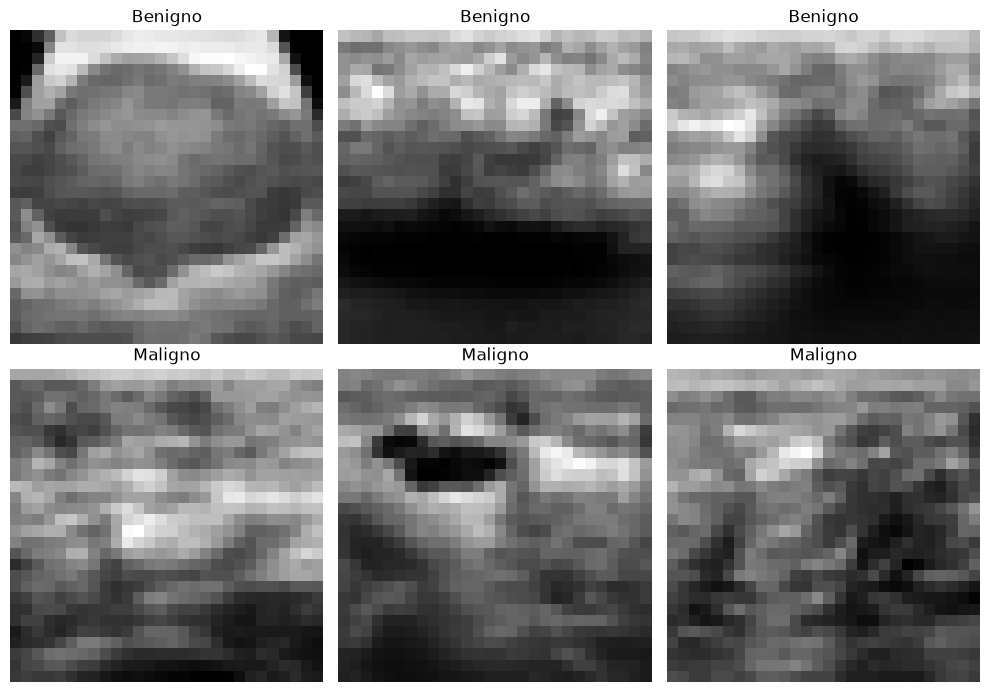

In [25]:
# TODO: Escribe tu código de visualización aquí
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for clase in [0, 1]:

    indices = np.where(y_train == clase)[0][:3]

    for i, idx in enumerate(indices):

        axes[clase, i].imshow(
            X_train[idx],
            cmap='gray'
        )

        axes[clase, i].set_title(
            "Benigno" if clase == 0 else "Maligno"
        )

        axes[clase, i].axis('off')

plt.tight_layout()
plt.show()

No se aprecia una diferencia visual obvia a simple vista. Debido a la baja resolución (28×28) y al ruido de la ecografía, ambas clases muestran masas oscuras con texturas similares, lo que hace indispensable el uso de métodos de aprendizaje automático para discriminarlas.

## 2. Preprocesamiento y Vectorización
Para aplicar PCA o SVD estándar, necesitamos que cada imagen (una matriz 2D de 28x28) se convierta en un vector 1D (784 píxeles).

### Consigna 2: Vectorización y Centrado
1. Transforma `X_train` y `X_test` de dimensiones `(N, 28, 28)` a `(N, 784)`.
2. Calcula el **rostro (imagen) medio** del conjunto de entrenamiento y réstalo a todas las imágenes (tanto de train como de test) para centrar los datos.

In [26]:
# TODO: Escribe tu código de preprocesamiento y centrado aquí
# Normalizar las imágenes entre 0 y 1
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# Vectorizar las imágenes
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Dimensiones entrenamiento:", X_train_flat.shape)
print("Dimensiones prueba:", X_test_flat.shape)

# Calcular la imagen promedio del entrenamiento
imagen_media = np.mean(X_train_flat, axis=0)

# Centrar los datos
X_train_centrado = X_train_flat - imagen_media
X_test_centrado = X_test_flat - imagen_media

print("Dimensiones centradas:", X_train_centrado.shape)

Dimensiones entrenamiento: (546, 784)
Dimensiones prueba: (156, 784)
Dimensiones centradas: (546, 784)


## 3. Reducción de Dimensionalidad con SVD / PCA
Ahora aplicaremos SVD a nuestra matriz de datos centrados para extraer los **Componentes Principales** (las "Eigen-imágenes").

### Consigna 3: Cálculo de SVD
1. Aplica SVD a la matriz de entrenamiento centrada para obtener `U`, `S` y `V^T`.
2. Grafica la varianza explicada acumulada y decide un valor de `r` (número de componentes) que conserve al menos el 90% de la energía/varianza.
3. Visualiza los primeros 5 componentes principales (Eigen-imágenes) redimensionándolos de nuevo a 28x28.

In [27]:
# TODO: Escribe tu código de SVD y visualización aquí
# Aplicar SVD sobre los datos centrados
U, S, VT = np.linalg.svd(
    X_train_centrado,
    full_matrices=False
)

print("Dimensión de U:", U.shape)
print("Dimensión de S:", S.shape)
print("Dimensión de VT:", VT.shape)

Dimensión de U: (546, 546)
Dimensión de S: (546,)
Dimensión de VT: (546, 784)


In [28]:
# Varianza explicada individual
varianza_explicada = (S ** 2) / np.sum(S ** 2)

# Varianza acumulada
varianza_acumulada = np.cumsum(varianza_explicada)

# Buscar componentes necesarios para conservar 90%
r_90 = np.argmax(varianza_acumulada >= 0.90) + 1

print("Componentes necesarios:", r_90)
print("Varianza acumulada:", varianza_acumulada[r_90 - 1] * 100, "%")

Componentes necesarios: 36
Varianza acumulada: 90.113434 %


Se eligen r=36 componentes principales, ya que con ellos se retiene el 90.11% de la varianza/energía de los datos, reduciendo la dimensión de 784 a solo 36 variables (una reducción de más del 95% de dimensionalidad)

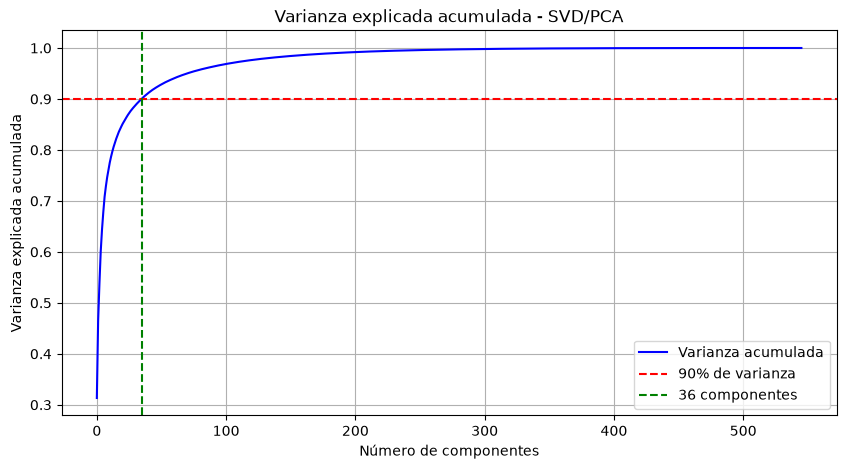

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    varianza_acumulada,
    color='blue',
    label='Varianza acumulada'
)

plt.axhline(
    y=0.90,
    color='red',
    linestyle='--',
    label='90% de varianza'
)

plt.axvline(
    x=r_90 - 1,
    color='green',
    linestyle='--',
    label=f'{r_90} componentes'
)

plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada acumulada - SVD/PCA")

plt.legend()
plt.grid()
plt.show()

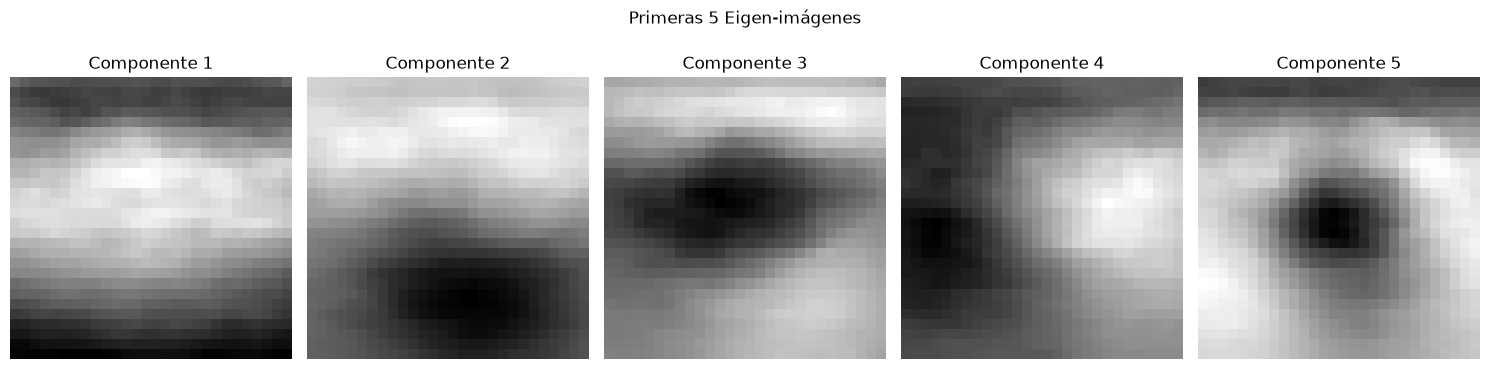

In [30]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i in range(5):

    componente = VT[i].reshape(28, 28)

    axes[i].imshow(
        componente,
        cmap='gray'
    )

    axes[i].set_title(f'Componente {i+1}')
    axes[i].axis('off')

plt.suptitle("Primeras 5 Eigen-imágenes")
plt.tight_layout()
plt.show()

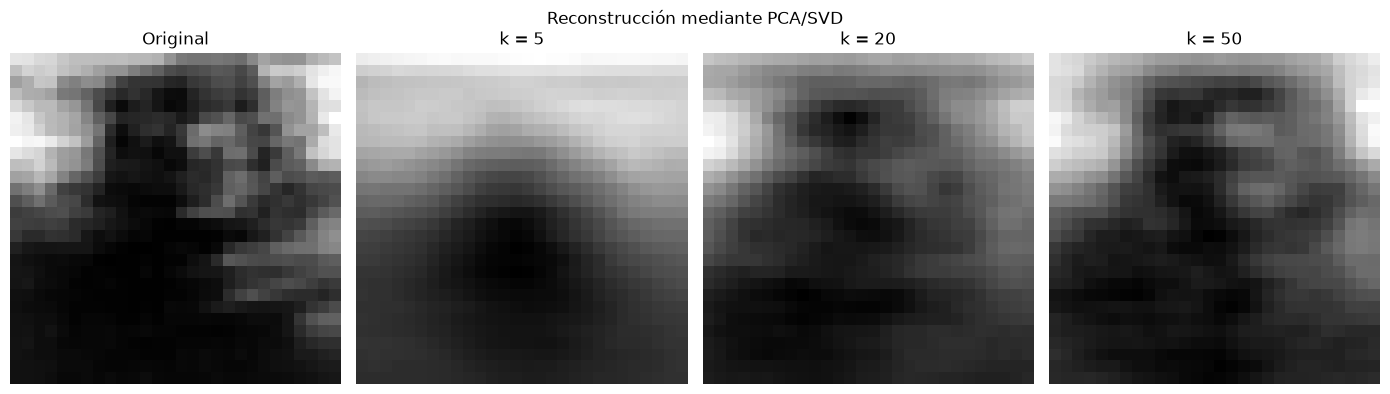

In [31]:
# Seleccionar una imagen de prueba
imagen_original = X_test_centrado[0]

valores_k = [5, 20, 50]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

# Imagen original
axes[0].imshow(
    X_test_flat[0].reshape(28, 28),
    cmap='gray'
)

axes[0].set_title("Original")
axes[0].axis('off')

for i, k in enumerate(valores_k):

    # Proyección
    proyeccion = imagen_original @ VT[:k].T

    # Reconstrucción
    reconstruccion = proyeccion @ VT[:k]

    # Recuperar el promedio
    reconstruccion += imagen_media

    axes[i+1].imshow(
        reconstruccion.reshape(28, 28),
        cmap='gray'
    )

    axes[i+1].set_title(f'k = {k}')
    axes[i+1].axis('off')

plt.suptitle("Reconstrucción mediante PCA/SVD")
plt.tight_layout()
plt.show()

## 4. Proyección y Clasificación
Una vez que tenemos la matriz de proyección (los primeros `r` componentes de `V^T` o equivalentemente usando Scikit-Learn `PCA`), proyectaremos los datos a un espacio de menor dimensión.

### Consigna 4: Clasificador Predictivo
1. Proyecta `X_train_centrado` y `X_test_centrado` sobre los primeros `r` componentes principales.
2. Entrena un clasificador simple, como **Regresión Logística** o **k-Nearest Neighbors (k-NN)**, usando las proyecciones de entrenamiento.
3. Evalúa el modelo en el conjunto de prueba usando `accuracy_score` y `classification_report`.
4. Prueba variar el número de componentes `r` (ej: 5, 20, 50) y describe cómo afecta el rendimiento.

In [32]:
# Elegir cantidad de componentes
r = r_90

# Proyectar entrenamiento y prueba
X_train_pca = X_train_centrado @ VT[:r].T
X_test_pca = X_test_centrado @ VT[:r].T

print("Entrenamiento reducido:", X_train_pca.shape)
print("Prueba reducida:", X_test_pca.shape)

Entrenamiento reducido: (546, 36)
Prueba reducida: (156, 36)


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# TODO: Escribe tu código de clasificación aquí
from sklearn.preprocessing import StandardScaler

# Normalizar las características proyectadas
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_pca)
X_test_scaled = scaler.transform(X_test_pca)

# Crear modelo
modelo = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Entrenar
modelo.fit(X_train_scaled, y_train)

# Predecir
y_pred = modelo.predict(X_test_scaled)

# Evaluar
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))


Accuracy: 0.7948717948717948

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.71      0.40      0.52        42
           1       0.81      0.94      0.87       114

    accuracy                           0.79       156
   macro avg       0.76      0.67      0.69       156
weighted avg       0.78      0.79      0.77       156



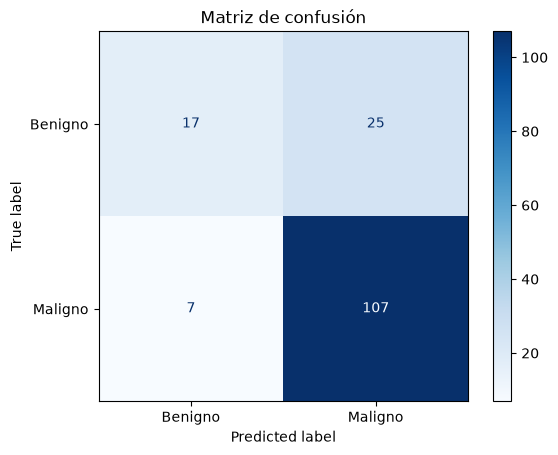

In [34]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benigno', 'Maligno']
)

disp.plot(cmap='Blues')

plt.title("Matriz de confusión")
plt.show()

In [35]:
resultados = []

for k in [5, 20, 50]:

    # Proyección
    X_train_k = X_train_centrado @ VT[:k].T
    X_test_k = X_test_centrado @ VT[:k].T

    # Escalamiento
    scaler_k = StandardScaler()

    X_train_k = scaler_k.fit_transform(X_train_k)
    X_test_k = scaler_k.transform(X_test_k)

    # Modelo
    modelo_k = LogisticRegression(
        max_iter=2000,
        random_state=42
    )

    inicio = time.time()

    modelo_k.fit(X_train_k, y_train)

    y_pred_k = modelo_k.predict(X_test_k)

    tiempo = time.time() - inicio

    accuracy_k = accuracy_score(y_test, y_pred_k)

    resultados.append({
        'Componentes': k,
        'Accuracy': accuracy_k,
        'Tiempo (s)': tiempo
    })

import pandas as pd

df_resultados = pd.DataFrame(resultados)

display(df_resultados)

,Componentes,Accuracy,Tiempo (s)
0,5,0.801282,0.005370
1,20,0.794872,0.000000
2,50,0.794872,0.003962


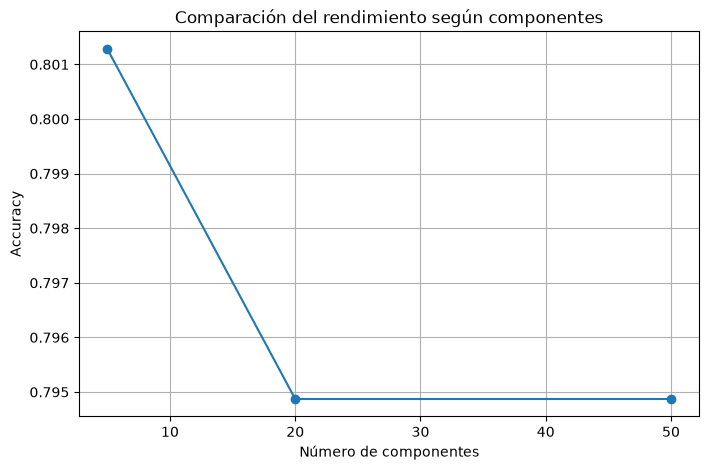

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_resultados['Componentes'],
    df_resultados['Accuracy'],
    marker='o'
)

plt.xlabel("Número de componentes")
plt.ylabel("Accuracy")
plt.title("Comparación del rendimiento según componentes")

plt.grid()
plt.show()

In [37]:
scaler_original = StandardScaler()

X_train_original = scaler_original.fit_transform(
    X_train_centrado
)

X_test_original = scaler_original.transform(
    X_test_centrado
)

modelo_original = LogisticRegression(
    max_iter=2000,
    random_state=42
)

inicio = time.time()

modelo_original.fit(X_train_original, y_train)

pred_original = modelo_original.predict(X_test_original)

tiempo_original = time.time() - inicio

accuracy_original = accuracy_score(
    y_test,
    pred_original
)

print("Accuracy original:", accuracy_original)
print("Tiempo original:", tiempo_original)

Accuracy original: 0.7628205128205128
Tiempo original: 0.08851265907287598


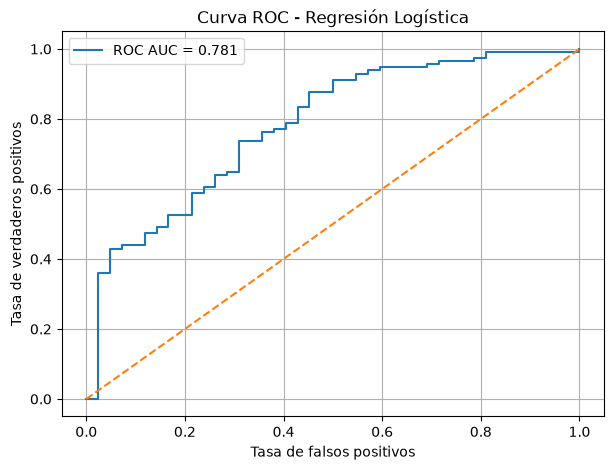

In [38]:
from sklearn.metrics import roc_curve, auc

# Probabilidades de la clase maligna
y_prob = modelo.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'ROC AUC = {roc_auc:.3f}'
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")

plt.title("Curva ROC - Regresión Logística")

plt.legend()
plt.grid()
plt.show()

### Consigna Opcional (Bonus)
Implementa un clasificador que, en lugar de usar un modelo externo como Regresión Logística, utilice directamente la reconstrucción de PCA. Por ejemplo, midiendo el error de reconstrucción de una imagen de prueba usando los componentes calculados únicamente sobre imágenes benignas vs imágenes malignas.